<a href="https://colab.research.google.com/github/diegotorresmauricio/Tesina/blob/main/tesina_Diego_M_Torres.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyección Estacional del Rendimiento de Soja en la Región Pampeana
### Trabajo Final — Licenciatura en Ciencia de Datos — Universidad del Gran Rosario

### Diego Mauricio Torres

**Fuentes:** MAGyP · ERA5 (Copernicus) · NOAA ONI · MODIS MOD13Q1 (Google Earth Engine)

> Todos los datos se leen desde `Google Drive/tesina_soja/`. Si un archivo ya existe, el notebook utiliza la copia almacenada y evita volver a descargarlo.

El análisis se desarrolla a escala departamental para la región pampeana y culmina con un contraste adicional a escala de lote.


## 1. Setup

Este bloque prepara el entorno de ejecución en Google Colab. Se instalan las librerías necesarias, se monta Google Drive y se crean las carpetas utilizadas para almacenar los datos originales, los datos procesados y las figuras.


In [1]:
!pip install geopandas rioxarray xarray netcdf4 xgboost earthengine-api cdsapi h3 --quiet

from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_ROOT = '/content/drive/MyDrive/tesina_soja'
for folder in ['raw/era5', 'raw/ndvi', 'raw/shp', 'processed', 'outputs/figures']:
    os.makedirs(f'{DRIVE_ROOT}/{folder}', exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import xarray as xr
import rioxarray
import requests, zipfile, io, warnings, pickle
from functools import reduce
from difflib import get_close_matches
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import xgboost as xgb

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
plt.rcParams['figure.dpi'] = 120

print(f"Drive montado. Raíz: {DRIVE_ROOT}")
print("Librerías cargadas.")

Mounted at /content/drive
Drive montado. Raíz: /content/drive/MyDrive/tesina_soja
Librerías cargadas.


## 2. Configuración

En este bloque se concentran los parámetros generales del proyecto: región de estudio, período temporal, cultivo, períodos fenológicos, variable objetivo y conjunto de variables utilizadas posteriormente en el modelo. Centralizar estos parámetros permite mantener consistente el procesamiento de las distintas fuentes.


In [2]:
from google.colab import userdata

GEE_PROJECT_ID = userdata.get('GEE_PROJECT_ID')
CDS_KEY        = userdata.get('CDS_KEY')

PROVINCIAS           = ['Buenos Aires', 'Córdoba', 'Santa Fe', 'Entre Ríos', 'La Pampa']
CULTIVO              = 'soja 1ra'
ANIO_INICIO          = 2000
ANIO_FIN             = 2024
ANIO_INICIO_VAL      = 2010
BBOX_PAMPEANA        = [-28, -66, -42, -56]
PERIODOS_FENOLOGICOS = {
    'siembra':   [10, 11],
    'floracion': [12, 1],
    'llenado':   [2, 3],
}
TARGET    = 'rinde'
FEATURES  = [
    'rinde_baseline', 'tendencia', 'oni_verano',
    'precip_siembra', 'temp_siembra',
    'precip_floracion', 'temp_floracion',
    'precip_llenado',
]

print("Configuración lista.")

Configuración lista.


## 3. Importaciones y utilidades GIS

Se cargan las herramientas específicas para el procesamiento y la visualización geográfica. También se define una función auxiliar para generar y guardar los mapas temáticos utilizados a lo largo del análisis.


In [3]:
from matplotlib.colors import TwoSlopeNorm
import geopandas as gpd
import matplotlib.pyplot as plt

In [4]:
# función para renderizar y guardar un mapa
def mapa(gdf_data, col, titulo, cmap='RdYlGn', vcenter=None, vmin=None, vmax=None,
         label_cbar='', fname=None, figsize=(10, 7)):

    fig, ax = plt.subplots(1, 1, figsize=figsize)

    if vcenter is not None:
        norm = TwoSlopeNorm(vmin=vmin or gdf_data[col].min(),
                            vcenter=vcenter,
                            vmax=vmax or gdf_data[col].max())
        gdf_data.plot(column=col, ax=ax, cmap=cmap, norm=norm,
                      edgecolor='white', linewidth=0.3, legend=True,
                      legend_kwds={'label': label_cbar, 'shrink': 0.7,
                                   'fraction': 0.03, 'pad': 0.02})
    else:
        gdf_data.plot(column=col, ax=ax, cmap=cmap,
                      vmin=vmin, vmax=vmax,
                      edgecolor='white', linewidth=0.3, legend=True,
                      legend_kwds={'label': label_cbar, 'shrink': 0.7,
                                   'fraction': 0.03, 'pad': 0.02,
                                   'orientation': 'vertical'})

    gdf_sin = gdf_data[gdf_data[col].isna()]
    if len(gdf_sin) > 0:
        gdf_sin.plot(ax=ax, color='#DDDDDD', edgecolor='white', linewidth=0.3)

    ax.set_title(titulo, fontsize=13, fontweight='bold', pad=10)
    ax.set_axis_off()
    plt.tight_layout()

    if fname:
        ruta = f'{DRIVE_ROOT}/outputs/figures/{fname}'
        plt.savefig(ruta, dpi=150, bbox_inches='tight')
        print(f"Guardado: {ruta}")
    plt.show()

## 4. MAGyP — Rendimiento de soja

La base del Ministerio de Agricultura, Ganadería y Pesca constituye la fuente de la variable objetivo del modelo. En este bloque se selecciona soja de primera para las provincias y campañas definidas, se normalizan los nombres de las variables y se obtiene la serie histórica de rendimiento por departamento y campaña.


In [5]:
RUTA_MAGYP_RAW  = f'{DRIVE_ROOT}/raw/magyp_estimaciones.csv'
RUTA_MAGYP_PROC = f'{DRIVE_ROOT}/processed/magyp_soja_pampa.parquet'
URL_MAGYP = (
    "https://datos.magyp.gob.ar/dataset/"
    "9e1e77ba-267e-4eaa-a59f-3296e86b5f36/resource/"
    "95d066e6-8a0f-4a80-b59d-6f28f88eacd5/download/"
    "estimaciones-agricolas-2026-03.csv"
)

if not os.path.exists(RUTA_MAGYP_RAW):
    print("Descargando magyp...")
    df_agro = pd.read_csv(URL_MAGYP, encoding='utf-8')
    if df_agro['provincia'].str.contains('Ã').any():
        for col in ['cultivo', 'provincia', 'departamento']:
            df_agro[col] = df_agro[col].str.encode('latin1').str.decode('utf-8', errors='replace')
    df_agro.to_csv(RUTA_MAGYP_RAW, index=False)
else:
    df_agro = pd.read_csv(RUTA_MAGYP_RAW)

if not os.path.exists(RUTA_MAGYP_PROC):
    df_soja = (
        df_agro
        .loc[df_agro['cultivo'] == CULTIVO]
        .loc[df_agro['provincia'].isin(PROVINCIAS)]
        .loc[df_agro['anio'].between(ANIO_INICIO, ANIO_FIN)]
        .rename(columns={'rendimiento_kgxha': 'rinde', 'superficie_sembrada_ha': 'sup_sembrada',
                         'superficie_cosechada_ha': 'sup_cosechada', 'produccion_tm': 'produccion'})
        .dropna(subset=['rinde'])
        .pipe(lambda df: df[df['rinde'] > 0])
        .copy()
    )
    df_soja.to_parquet(RUTA_MAGYP_PROC, index=False)
else:
    df_soja = pd.read_parquet(RUTA_MAGYP_PROC)

print(f"Registros: {len(df_soja)} | Campañas: {df_soja['anio'].min()}–{df_soja['anio'].max()} | Departamentos: {df_soja['departamento'].nunique()}")
display(df_soja.head())

Registros: 4098 | Campañas: 2000–2024 | Departamentos: 171


,cultivo,anio,campania,provincia,provincia_id,departamento,departamento_id,sup_sembrada,sup_cosechada,produccion,rinde
0,soja 1ra,2000,2000/2001,Buenos Aires,6.00,Carlos Tejedor,6154.00,25500,24000,60000,2500
1,soja 1ra,2000,2000/2001,Buenos Aires,6.00,Carlos Casares,6147.00,42000,40000,108000,2700
2,soja 1ra,2000,2000/2001,Buenos Aires,6.00,Capitán Sarmiento,6140.00,25000,25000,80000,3200
3,soja 1ra,2000,2000/2001,Buenos Aires,6.00,Cañuelas,6134.00,1080,1080,3500,3241
4,soja 1ra,2000,2000/2001,Buenos Aires,6.00,Alberti,6021.00,9000,7200,20200,2806


## 5. Shapefile de departamentos (INDEC)

Se incorpora la información geográfica de los departamentos de la región de estudio. Esta capa permite vincular los datos productivos y ambientales con su ubicación espacial y constituye la base para los mapas temáticos posteriores.


In [6]:
RUTA_SHP = f'{DRIVE_ROOT}/raw/shp/deptos_indec.gpkg'

if not os.path.exists(RUTA_SHP):
    resp = requests.get("https://www.indec.gob.ar/ftp/cuadros/territorio/codgeo/Codgeo_Pais_x_dpto_con_datos.zip", timeout=60)
    z = zipfile.ZipFile(io.BytesIO(resp.content))
    z.extractall('/tmp/deptos_indec/')
    shp = [f for f in os.listdir('/tmp/deptos_indec/') if f.endswith('.shp')][0]
    gdf = gpd.read_file(f'/tmp/deptos_indec/{shp}')
    gdf.to_file(RUTA_SHP, driver='GPKG')
else:
    gdf = gpd.read_file(RUTA_SHP)

gdf_pampa = (
    gdf[gdf['provincia'].isin(PROVINCIAS)]
    .to_crs('EPSG:4326')
    .rename(columns={'departamen': 'departamento'})
    [['departamento', 'provincia', 'geometry']]
    .copy()
)
print(f"Departamentos pampeanos: {len(gdf_pampa)}")

Departamentos pampeanos: 218


In [7]:
# Preparar datos para mapas
gdf = gpd.read_file(f'{DRIVE_ROOT}/raw/shp/deptos_indec.gpkg')
gdf_pampa = (
    gdf[gdf['provincia'].isin(PROVINCIAS)]
    .to_crs('EPSG:4326')
    .rename(columns={'departamen': 'departamento'})
    [['departamento', 'provincia', 'geometry']]
    .copy()
)

df_map = pd.read_parquet(f'{DRIVE_ROOT}/processed/dataset_final.parquet')

# fase_enso calculada directamente desde oni_verano
df_map['fase_enso'] = pd.cut(
    df_map['oni_verano'],
    bins=[-999, -0.5, 0.5, 999],
    labels=['Niña', 'Neutro', 'Niño']
)

print(f"Departamentos en shapefile: {len(gdf_pampa)}")
print(f"Departamentos en dataset:   {df_map['departamento'].nunique()}")

Departamentos en shapefile: 218
Departamentos en dataset:   167


## 6. Análisis exploratorio — rendimiento de soja

Antes de construir el modelo, se explora el comportamiento histórico del rendimiento de soja. El objetivo de este bloque es caracterizar su distribución temporal y espacial e identificar la variabilidad existente entre departamentos y campañas.


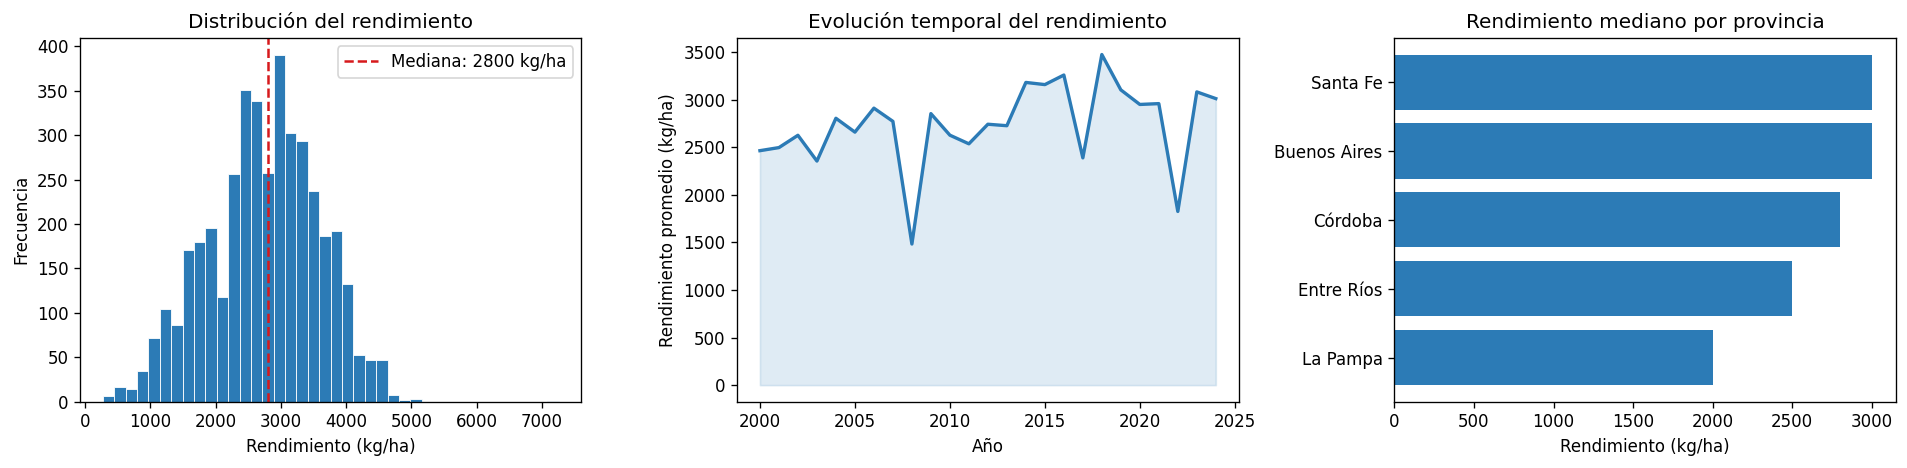

,count,mean,std,min,25%,50%,75%,max
provincia,,,,,,,,
Buenos Aires,2343.00,2875.00,842.00,272.00,2300.00,3000.00,3500.00,5000.00
Córdoba,570.00,2718.00,747.00,900.00,2200.00,2799.00,3269.00,4396.00
Entre Ríos,397.00,2391.00,622.00,597.00,2100.00,2500.00,2800.00,3699.00
La Pampa,314.00,2085.00,817.00,500.00,1500.00,2000.00,2646.00,4000.00
Santa Fe,474.00,2861.00,894.00,361.00,2312.00,3000.00,3500.00,7253.00


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(df_soja['rinde'], bins=40, color='#2C7BB6', edgecolor='white', linewidth=0.5)
axes[0].axvline(df_soja['rinde'].median(), color='#D7191C', linestyle='--',
                label=f"Mediana: {df_soja['rinde'].median():.0f} kg/ha")
axes[0].set_title('Distribución del rendimiento')
axes[0].set_xlabel('Rendimiento (kg/ha)'); axes[0].set_ylabel('Frecuencia'); axes[0].legend()

rinde_anio = df_soja.groupby('anio')['rinde'].mean()
axes[1].plot(rinde_anio.index, rinde_anio.values, color='#2C7BB6', linewidth=2)
axes[1].fill_between(rinde_anio.index, rinde_anio.values, alpha=0.15, color='#2C7BB6')
axes[1].set_title('Evolución temporal del rendimiento')
axes[1].set_xlabel('Año'); axes[1].set_ylabel('Rendimiento promedio (kg/ha)')

rinde_prov = df_soja.groupby('provincia')['rinde'].median().sort_values()
axes[2].barh(rinde_prov.index, rinde_prov.values, color='#2C7BB6')
axes[2].set_title('Rendimiento mediano por provincia')
axes[2].set_xlabel('Rendimiento (kg/ha)')

plt.tight_layout()
plt.savefig(f'{DRIVE_ROOT}/outputs/figures/eda_magyp.png', bbox_inches='tight')
plt.show()

display(df_soja.groupby('provincia')['rinde'].describe().round(0))

### Distribución espacial del rendimiento

El primer mapa permite observar cómo se distribuye espacialmente el rendimiento promedio histórico de soja de primera. El segundo caracteriza la variabilidad interanual mediante el desvío estándar, complementando la información sobre el nivel medio de rendimiento con su estabilidad a lo largo del período analizado.


Guardado: /content/drive/MyDrive/tesina_soja/outputs/figures/mapa_01_rinde_promedio.png


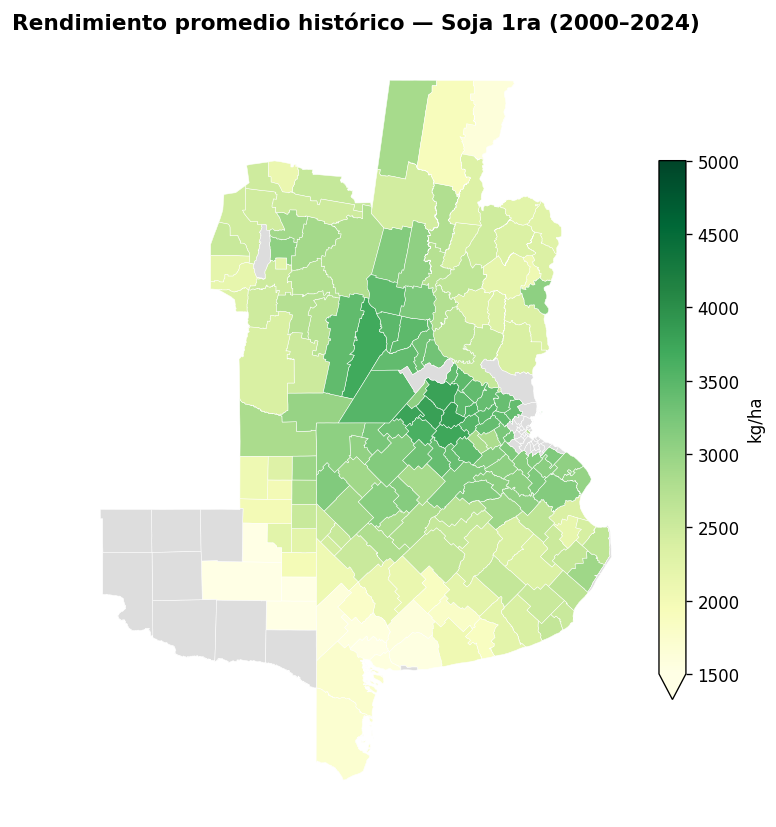

In [9]:
# Rendimiento promedio histórico por departamento
rinde_prom = (
    df_map.groupby('departamento')['rinde']
    .mean().reset_index()
    .rename(columns={'rinde': 'rinde_prom'})
)
gdf_m1 = gdf_pampa.merge(rinde_prom, on='departamento', how='left')

mapa(gdf_m1, 'rinde_prom',
     'Rendimiento promedio histórico — Soja 1ra (2000–2024)',
     cmap='YlGn', vmin=1500, vmax=5000,
     label_cbar='kg/ha',
     fname='mapa_01_rinde_promedio.png')

Guardado: /content/drive/MyDrive/tesina_soja/outputs/figures/mapa_02_variabilidad.png


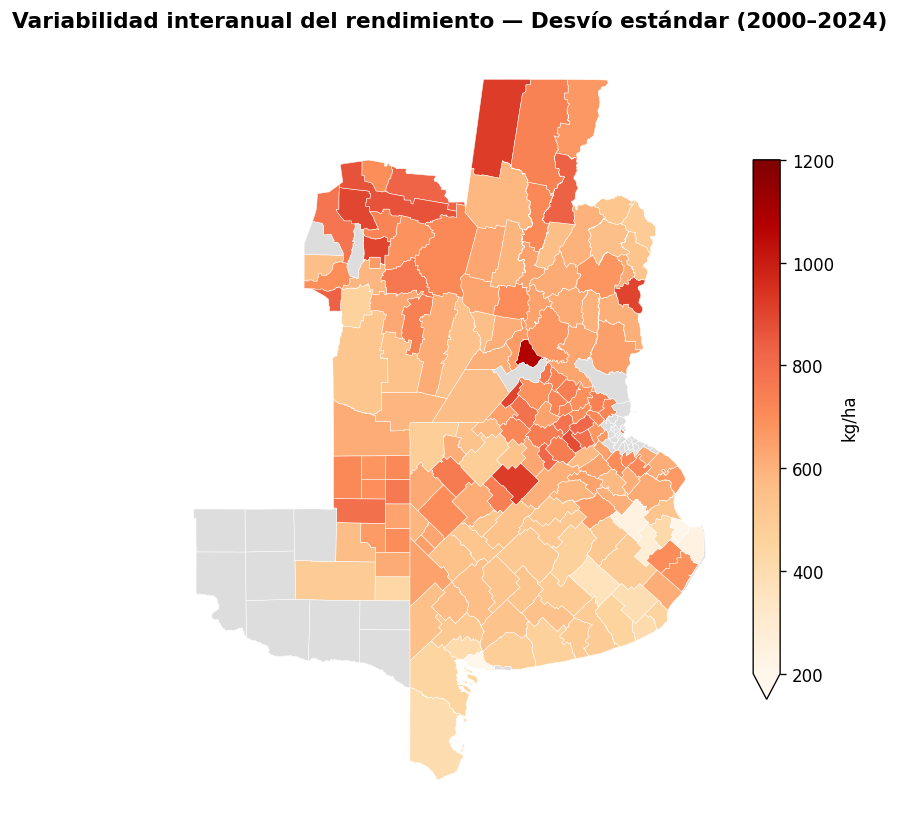

In [10]:
# Variabilidad interanual (desvío estándar)
rinde_std = (
    df_map.groupby('departamento')['rinde']
    .std().reset_index()
    .rename(columns={'rinde': 'rinde_std'})
)
gdf_m2 = gdf_pampa.merge(rinde_std, on='departamento', how='left')

mapa(gdf_m2, 'rinde_std',
     'Variabilidad interanual del rendimiento — Desvío estándar (2000–2024)',
     cmap='OrRd', vmin=200, vmax=1200,
     label_cbar='kg/ha',
     fname='mapa_02_variabilidad.png')

## 7. ENSO — Índice Oceánico Niño (NOAA)

Se incorpora el Índice Oceánico Niño (ONI) como indicador de las condiciones ENSO. Se utiliza el promedio correspondiente al verano austral (DJF–FMA), de acuerdo con la definición adoptada en el proyecto, para representar una señal climática de escala regional asociada al ciclo del cultivo.


Distribución de fases ENSO:
fase_enso
Neutro    34
Niña      23
Niño      20
Name: count, dtype: int64


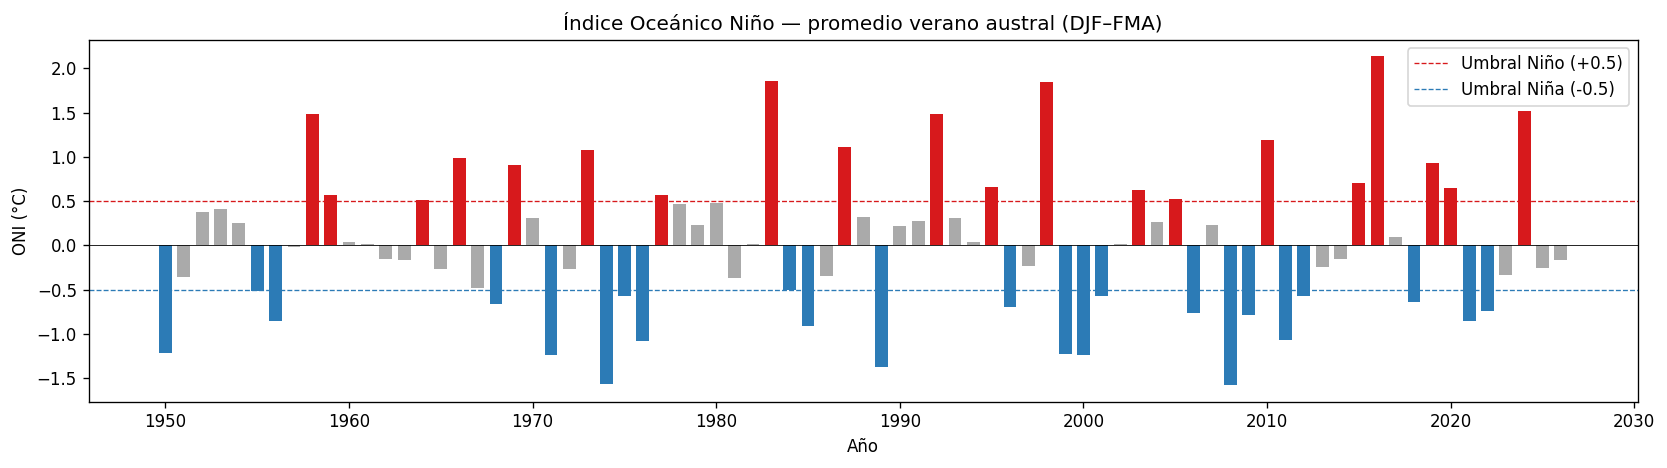

In [11]:
RUTA_ONI_RAW  = f'{DRIVE_ROOT}/raw/oni.csv'
RUTA_ONI_PROC = f'{DRIVE_ROOT}/processed/enso_por_campania.parquet'

if not os.path.exists(RUTA_ONI_RAW):
    resp = requests.get("https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt", timeout=15)
    rows = []
    for line in resp.text.strip().split('\n'):
        parts = line.split()
        if len(parts) >= 4 and parts[0] != 'SEAS':
            try: rows.append({'trimestre': parts[0], 'anio': int(parts[1]), 'oni': float(parts[3])})
            except ValueError: continue
    df_oni = pd.DataFrame(rows)
    df_oni.to_csv(RUTA_ONI_RAW, index=False)
else:
    df_oni = pd.read_csv(RUTA_ONI_RAW)

if not os.path.exists(RUTA_ONI_PROC):
    def clasificar_enso(oni):
        if oni >= 0.5: return 'Niño'
        elif oni <= -0.5: return 'Niña'
        else: return 'Neutro'

    df_enso = (
        df_oni[df_oni['trimestre'].isin(['DJF', 'JFM', 'FMA'])]
        .groupby('anio')['oni'].mean().reset_index()
        .rename(columns={'oni': 'oni_verano'})
    )
    df_enso['fase_enso'] = df_enso['oni_verano'].apply(clasificar_enso)
    df_enso.to_parquet(RUTA_ONI_PROC, index=False)
else:
    df_enso = pd.read_parquet(RUTA_ONI_PROC)

print("Distribución de fases ENSO:"); print(df_enso['fase_enso'].value_counts())

fig, ax = plt.subplots(figsize=(14, 4))
colores = df_enso['oni_verano'].apply(lambda x: '#D7191C' if x >= 0.5 else ('#2C7BB6' if x <= -0.5 else '#AAAAAA'))
ax.bar(df_enso['anio'], df_enso['oni_verano'], color=colores, width=0.7)
ax.axhline( 0.5, color='#D7191C', linestyle='--', linewidth=0.8, label='Umbral Niño (+0.5)')
ax.axhline(-0.5, color='#2C7BB6', linestyle='--', linewidth=0.8, label='Umbral Niña (-0.5)')
ax.axhline(0, color='black', linewidth=0.5)
ax.set_title('Índice Oceánico Niño — promedio verano austral (DJF–FMA)')
ax.set_xlabel('Año'); ax.set_ylabel('ONI (°C)'); ax.legend()
plt.tight_layout()
plt.savefig(f'{DRIVE_ROOT}/outputs/figures/oni_serie.png', bbox_inches='tight')
plt.show()

### Distribución espacial del rendimiento por fase ENSO

Se compara el rendimiento departamental según las fases Niño, Neutro y Niña. Además de visualizar las diferencias espaciales entre fases, se calcula la diferencia porcentual entre Niño y Niña para cuantificar el contraste asociado a estas condiciones climáticas.


Guardado: /content/drive/MyDrive/tesina_soja/outputs/figures/mapa_03_rinde_por_enso.png


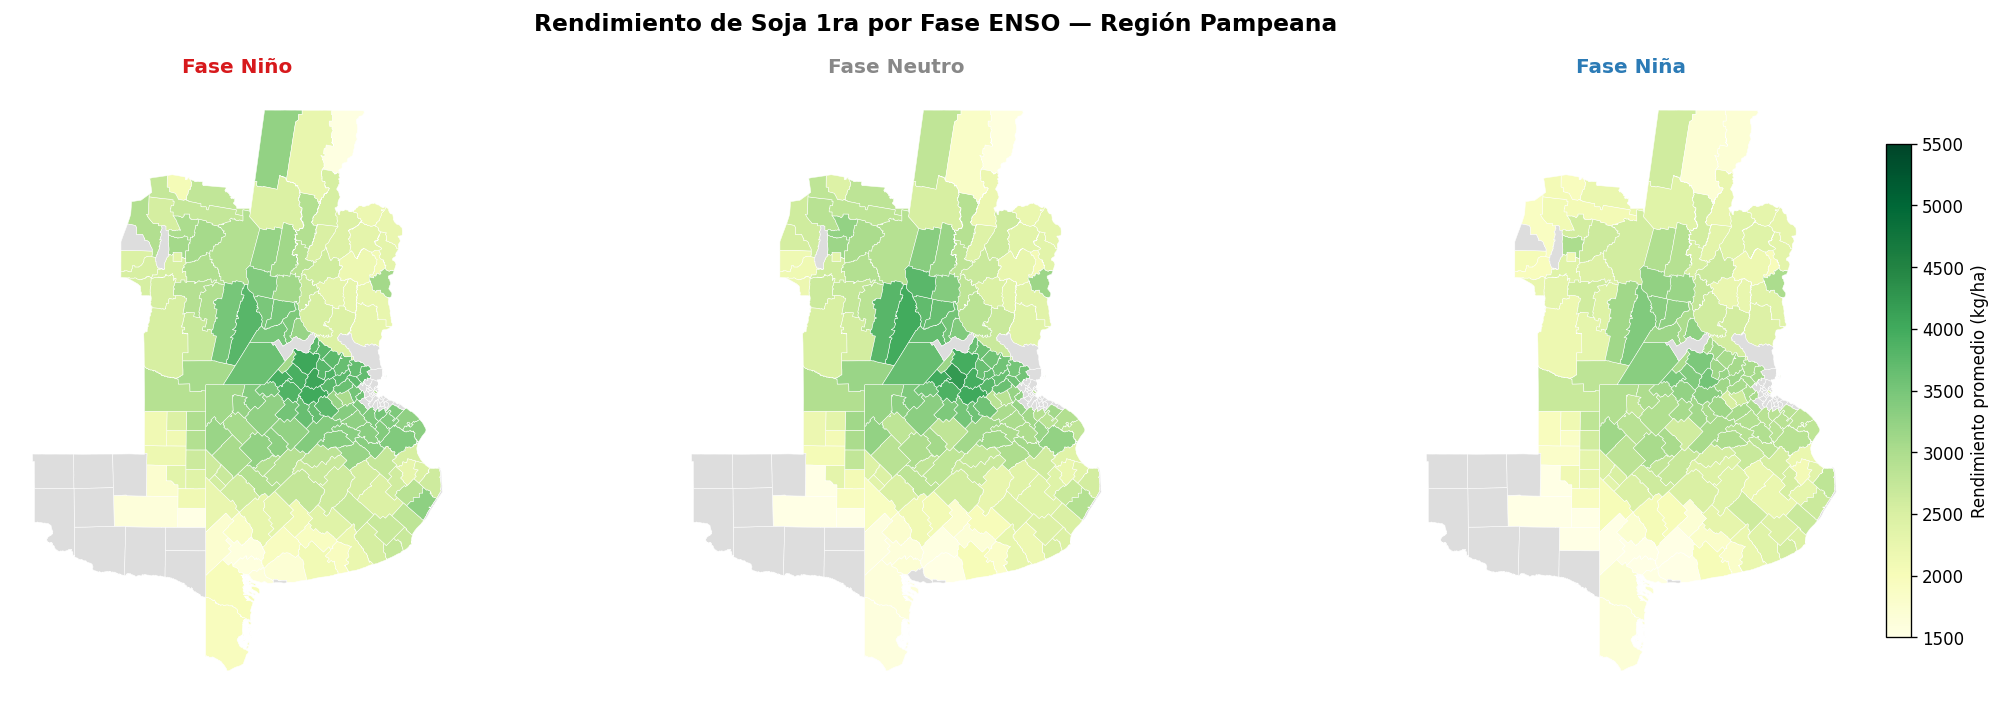

In [12]:
# Rendimiento por fase ENSO
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fases = ['Niño', 'Neutro', 'Niña']
colores_titulo = ['#D7191C', '#888888', '#2C7BB6']
vmin_enso, vmax_enso = 1500, 5500

for ax, fase, color in zip(axes, fases, colores_titulo):
    rinde_fase = (
        df_map[df_map['fase_enso'] == fase]
        .groupby('departamento')['rinde']
        .mean().reset_index()
        .rename(columns={'rinde': 'rinde_fase'})
    )
    gdf_fase = gdf_pampa.merge(rinde_fase, on='departamento', how='left')
    gdf_fase.plot(column='rinde_fase', ax=ax, cmap='YlGn',
                  vmin=vmin_enso, vmax=vmax_enso,
                  edgecolor='white', linewidth=0.3)
    gdf_fase[gdf_fase['rinde_fase'].isna()].plot(
        ax=ax, color='#DDDDDD', edgecolor='white', linewidth=0.3)
    ax.set_title(f'Fase {fase}', fontsize=12, fontweight='bold', color=color)
    ax.set_axis_off()

# Colorbar a la derecha del último mapa, no superpuesta
sm = plt.cm.ScalarMappable(cmap='YlGn',
     norm=plt.Normalize(vmin=vmin_enso, vmax=vmax_enso))
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes[-1], shrink=0.8, pad=0.04, fraction=0.046)
cbar.set_label('Rendimiento promedio (kg/ha)', fontsize=10)

fig.suptitle('Rendimiento de Soja 1ra por Fase ENSO — Región Pampeana',
             fontsize=14, fontweight='bold')
plt.tight_layout()
ruta = f'{DRIVE_ROOT}/outputs/figures/mapa_03_rinde_por_enso.png'
plt.savefig(ruta, dpi=150, bbox_inches='tight')
print(f"Guardado: {ruta}")
plt.show()

Guardado: /content/drive/MyDrive/tesina_soja/outputs/figures/mapa_04_diff_nino_nina.png


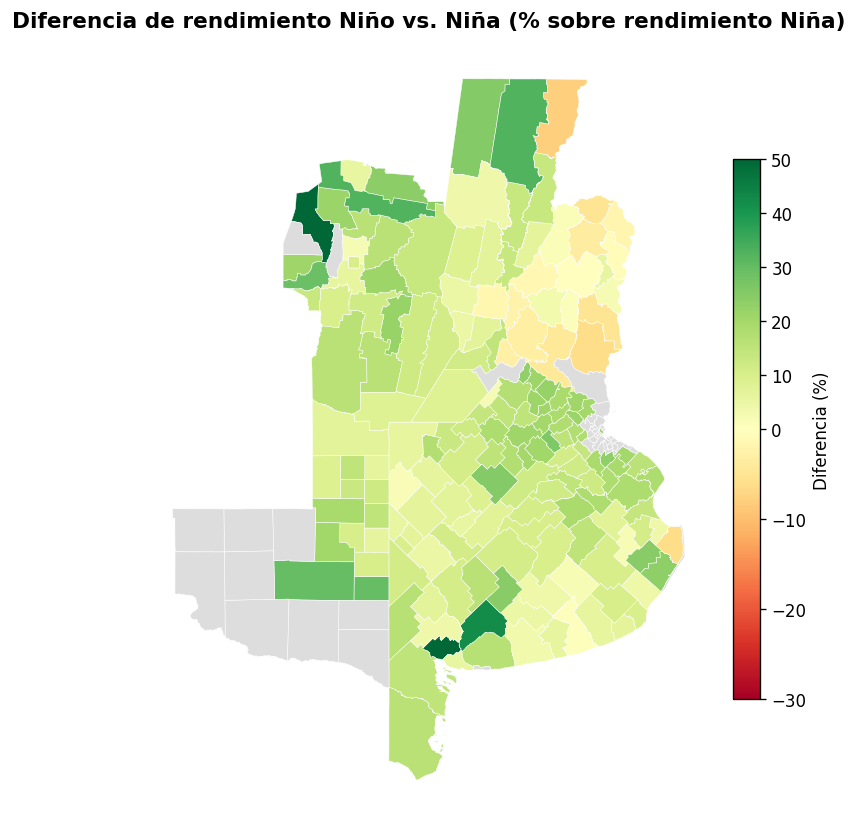

In [13]:
# Diferencia Niño vs Niña por departamento
rinde_nino = (df_map[df_map['fase_enso']=='Niño']
              .groupby('departamento')['rinde'].mean())
rinde_nina = (df_map[df_map['fase_enso']=='Niña']
              .groupby('departamento')['rinde'].mean())

diff_enso = ((rinde_nino - rinde_nina) / rinde_nina * 100).reset_index()
diff_enso.columns = ['departamento', 'diff_pct']

gdf_m4 = gdf_pampa.merge(diff_enso, on='departamento', how='left')

mapa(gdf_m4, 'diff_pct',
     'Diferencia de rendimiento Niño vs. Niña (% sobre rendimiento Niña)',
     cmap='RdYlGn', vcenter=0, vmin=-30, vmax=50,
     label_cbar='Diferencia (%)',
     fname='mapa_04_diff_nino_nina.png')

## 8. ERA5 — Variables climáticas (Copernicus)

Se incorporan datos climáticos de ERA5 para complementar el indicador ENSO con información de escala local/regional. En particular, se utilizan precipitación y temperatura mensual para el período 2000–2024 y para la región pampeana definida en la configuración.


In [14]:
import cdsapi
cdsapirc = f"url: https://cds.climate.copernicus.eu/api\nkey: {CDS_KEY}\n"
with open(os.path.expanduser('~/.cdsapirc'), 'w') as f:
    f.write(cdsapirc)
client = cdsapi.Client()

RUTA_ERA5_ZIP  = f'{DRIVE_ROOT}/raw/era5/era5_2000_2024.zip'
RUTA_ERA5_TEMP = f'{DRIVE_ROOT}/raw/era5/era5_temperatura.nc'
RUTA_ERA5_PREC = f'{DRIVE_ROOT}/raw/era5/era5_precipitacion.nc'

if not os.path.exists(RUTA_ERA5_ZIP):
    print("Descargando ERA5 2000–2024 (puede tardar)...")
    client.retrieve(
        'reanalysis-era5-single-levels-monthly-means',
        {
            'product_type': ['monthly_averaged_reanalysis'],
            'variable': ['total_precipitation', '2m_temperature'],
            'year': [str(a) for a in range(ANIO_INICIO, ANIO_FIN + 1)],
            'month': [f'{m:02d}' for m in range(1, 13)],
            'time': ['00:00'], 'data_format': 'netcdf',
            'download_format': 'unarchived', 'area': BBOX_PAMPEANA,
        },
        RUTA_ERA5_ZIP
    )

if not os.path.exists(RUTA_ERA5_TEMP) or not os.path.exists(RUTA_ERA5_PREC):
    import glob
    with zipfile.ZipFile(RUTA_ERA5_ZIP, 'r') as z:
        z.extractall(f'{DRIVE_ROOT}/raw/era5/')
    for nc in glob.glob(f'{DRIVE_ROOT}/raw/era5/*.nc'):
        ds_tmp = xr.open_dataset(nc, engine='netcdf4')
        vars_in = list(ds_tmp.data_vars); ds_tmp.close()
        if 't2m' in vars_in: os.rename(nc, RUTA_ERA5_TEMP)
        elif 'tp' in vars_in: os.rename(nc, RUTA_ERA5_PREC)

ds_temp = xr.open_dataset(RUTA_ERA5_TEMP, engine='netcdf4')
ds_prec = xr.open_dataset(RUTA_ERA5_PREC, engine='netcdf4')
ds_temp['t2m_c'] = ds_temp['t2m'] - 273.15
ds_prec['tp_mm'] = ds_prec['tp'] * 1000
print("ERA5 cargado.")

2026-10-29 22:57:54,488 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
INFO:ecmwf.datastores.legacy_client:[2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.


ERA5 cargado.


## 9. ERA5 → Agregación por departamento y período fenológico

Los datos climáticos se transforman para obtener variables representativas de cada departamento y de los períodos fenológicos definidos para el cultivo: siembra, floración y llenado. Esta agregación permite integrar la información climática con la escala espacial y temporal de los rendimientos agrícolas.


In [15]:
RUTA_ERA5_PROC = f'{DRIVE_ROOT}/processed/era5_departamentos.parquet'

def era5_a_departamentos(ds, variable, gdf):
    da = ds[variable].rio.write_crs('EPSG:4326')
    resultados = []
    for _, depto in gdf.iterrows():
        try:
            da_clip = da.rio.clip([depto.geometry], crs='EPSG:4326', drop=True)
            prom = da_clip.mean(dim=['latitude', 'longitude'])
            for i, t in enumerate(ds['valid_time'].values):
                ts = pd.Timestamp(t)
                resultados.append({'departamento': depto['departamento'], 'provincia': depto['provincia'],
                                   'anio': ts.year, 'mes': ts.month, variable: float(prom.values[i])})
        except Exception: continue
    return pd.DataFrame(resultados)

if not os.path.exists(RUTA_ERA5_PROC):
    print("Agregando ERA5 por departamento...")
    df_temp_d = era5_a_departamentos(ds_temp, 't2m_c', gdf_pampa)
    df_prec_d = era5_a_departamentos(ds_prec, 'tp_mm', gdf_pampa)
    df_clima  = df_temp_d.merge(df_prec_d[['departamento', 'provincia', 'anio', 'mes', 'tp_mm']],
                                on=['departamento', 'provincia', 'anio', 'mes'])
    dfs = []
    for periodo, meses in PERIODOS_FENOLOGICOS.items():
        df_p = df_clima.copy()
        if 12 in meses:
            df_p['anio_campania'] = df_p.apply(lambda r: r['anio'] + 1 if r['mes'] == 12 else r['anio'], axis=1)
        else:
            df_p['anio_campania'] = df_p['anio']
        df_p = (df_p[df_p['mes'].isin(meses)]
                .groupby(['departamento', 'provincia', 'anio_campania'])
                .agg(temp=('t2m_c', 'mean'), precip=('tp_mm', 'sum')).reset_index()
                .rename(columns={'anio_campania': 'anio', 'temp': f'temp_{periodo}', 'precip': f'precip_{periodo}'}))
        dfs.append(df_p)
    df_era5_final = reduce(lambda a, b: a.merge(b, on=['departamento', 'provincia', 'anio']), dfs)
    df_era5_final.to_parquet(RUTA_ERA5_PROC, index=False)
else:
    df_era5_final = pd.read_parquet(RUTA_ERA5_PROC)

print(f"ERA5 procesado: {df_era5_final.shape}")
display(df_era5_final.head())

ERA5 procesado: (4700, 9)


,departamento,provincia,anio,temp_siembra,precip_siembra,temp_floracion,precip_floracion,temp_llenado,precip_llenado
0,25 de Mayo,Buenos Aires,2000,16.17,8.84,24.15,2.04,20.39,9.31
1,25 de Mayo,Buenos Aires,2001,17.23,12.87,22.14,6.39,21.99,11.31
2,25 de Mayo,Buenos Aires,2002,18.34,12.07,22.19,4.76,20.22,12.76
3,25 de Mayo,Buenos Aires,2003,17.78,12.28,22.36,6.17,21.04,6.72
4,25 de Mayo,Buenos Aires,2004,16.78,5.98,21.68,6.39,21.13,2.49


## 10. NDVI — Google Earth Engine (MODIS MOD13Q1)

Se incorpora información satelital de NDVI obtenida a partir de MODIS MOD13Q1 mediante Google Earth Engine. El objetivo es evaluar si una medida de comportamiento de la vegetación durante el ciclo del cultivo aporta información predictiva adicional respecto de las variables productivas, climáticas y ENSO.


In [16]:
import ee
ee.Authenticate()
ee.Initialize(project=GEE_PROJECT_ID)

# Verificar estado de exportaciones previas
tasks = ee.batch.Task.list()
for t in tasks[:3]:
    print(f"{t.config['description']:<30} Estado: {t.state}")

In [17]:
# Exportar NDVI a Drive (solo si no existe el CSV)
RUTA_NDVI_CSV = '/content/drive/MyDrive/tesina_soja raw ndvi/ndvi_pampeana.csv'

def exportar_ndvi_a_drive():
    provincias_gee = ['Buenos Aires', 'Cordoba', 'Santa Fe', 'Entre Rios', 'La Pampa']
    deptos = (ee.FeatureCollection("FAO/GAUL/2015/level2")
              .filter(ee.Filter.eq('ADM0_NAME', 'Argentina'))
              .filter(ee.Filter.inList('ADM1_NAME', provincias_gee)))

    def ndvi_anio(anio):
        anio = ee.Number(anio)
        coleccion = (ee.ImageCollection('MODIS/061/MOD13Q1')
                     .filterDate(ee.Date.fromYMD(anio, 10, 1), ee.Date.fromYMD(anio.add(1), 4, 30))
                     .select('NDVI'))
        ndvi_max = ee.Image(ee.Algorithms.If(
            coleccion.size().gt(0),
            coleccion.map(lambda img: img.multiply(0.0001)).max(),
            ee.Image.constant(0).rename('NDVI')
        ))
        def reducir(feat):
            stats = ndvi_max.reduceRegion(reducer=ee.Reducer.mean(), geometry=feat.geometry(), scale=250, maxPixels=1e9)
            return feat.set({'ndvi_max': stats.get('NDVI', None), 'anio': anio})
        return deptos.map(reducir)

    coleccion = ee.FeatureCollection(ee.List(list(range(ANIO_INICIO, ANIO_FIN + 1))).map(ndvi_anio)).flatten()
    task = ee.batch.Export.table.toDrive(
        collection=coleccion, description='ndvi_pampeana',
        folder='tesina_soja/raw/ndvi', fileNamePrefix='ndvi_pampeana',
        fileFormat='CSV', selectors=['ADM1_NAME', 'ADM2_NAME', 'anio', 'ndvi_max']
    )
    task.start()
    print(f"Exportación iniciada: {task.id}")

if not os.path.exists(RUTA_NDVI_CSV):
    exportar_ndvi_a_drive()
    print("Ejecutar la celda siguiente cuando la tarea esté COMPLETED.")
else:
    print("NDVI CSV ya disponible en Drive.")

NDVI CSV ya disponible en Drive.


In [18]:
# Cargar y procesar NDVI
df_ndvi_raw = pd.read_csv(RUTA_NDVI_CSV)
df_ndvi = df_ndvi_raw.rename(columns={'ADM1_NAME': 'provincia', 'ADM2_NAME': 'departamento'}).copy()
print(f"NDVI cargado: {df_ndvi.shape}")
display(df_ndvi.head())

NDVI cargado: (5450, 4)


,provincia,departamento,anio,ndvi_max
0,Buenos Aires,Florencio Varela,2000,0.70
1,Buenos Aires,Presidente Peron,2000,0.77
2,Buenos Aires,San Vicente,2000,0.79
3,Buenos Aires,Canuelas,2000,0.80
4,Buenos Aires,Esteban Echeverria,2000,0.66


### Distribución espacial del NDVI

Se presenta la distribución espacial del NDVI máximo utilizado en el dataset, como caracterización descriptiva de la señal de vegetación incorporada al análisis.


Guardado: /content/drive/MyDrive/tesina_soja/outputs/figures/mapa_07_ndvi_promedio.png


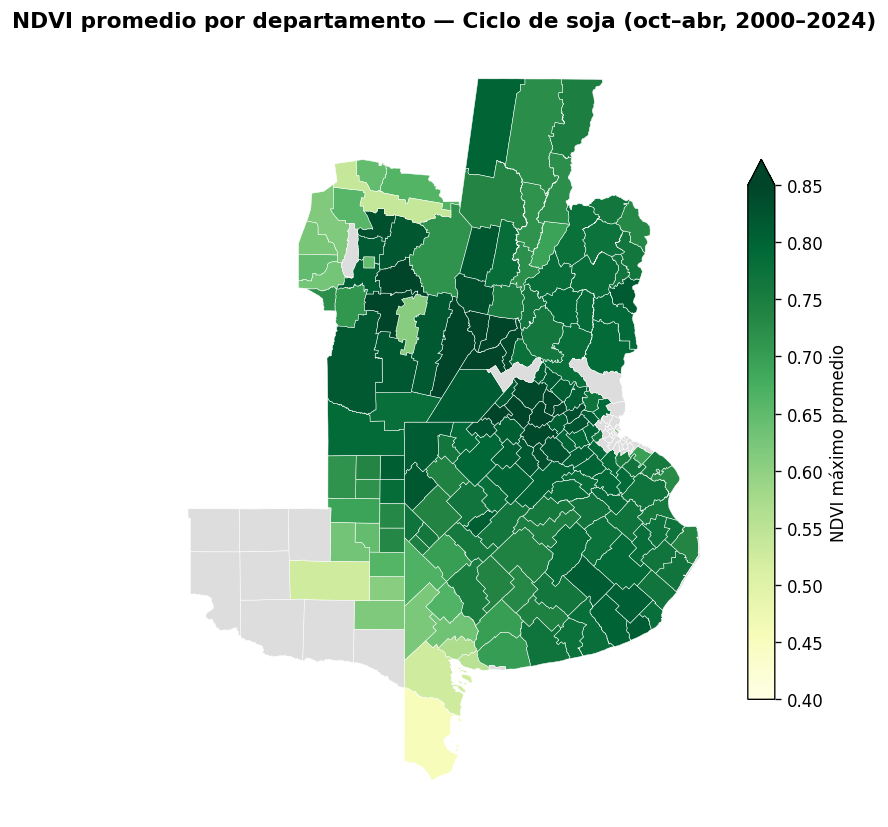

In [19]:
# NDVI promedio por departamento
ndvi_prom = (df_map.groupby('departamento')['ndvi_max']
             .mean().reset_index()
             .rename(columns={'ndvi_max': 'ndvi_prom'}))

gdf_m7 = gdf_pampa.merge(ndvi_prom, on='departamento', how='left')

mapa(gdf_m7, 'ndvi_prom',
     'NDVI promedio por departamento — Ciclo de soja (oct–abr, 2000–2024)',
     cmap='YlGn', vmin=0.4, vmax=0.85,
     label_cbar='NDVI máximo promedio',
     fname='mapa_07_ndvi_promedio.png')

## 11. Dataset integrado

En este bloque se reúnen las distintas fuentes procesadas en una única base de análisis. El resultado combina rendimiento histórico, información climática, ENSO y NDVI a escala departamental y por campaña, dejando los datos preparados para la etapa de modelado.


In [20]:
RUTA_DATASET = f'{DRIVE_ROOT}/processed/dataset_modelo.parquet'

df_modelo = df_soja.merge(df_enso, on='anio', how='left')
df_modelo = df_modelo.merge(df_era5_final, on=['departamento', 'provincia', 'anio'], how='left')
df_modelo.to_parquet(RUTA_DATASET, index=False)

print(f"Shape: {df_modelo.shape}")
print("\n=== Completitud ===")
for col in df_modelo.columns:
    n = df_modelo[col].isna().sum()
    if n > 0: print(f"  {col:<30} {n:>5} nulos ({n/len(df_modelo)*100:.1f}%)")
display(df_modelo.head())

Shape: (4098, 19)

=== Completitud ===
  temp_siembra                      77 nulos (1.9%)
  precip_siembra                    77 nulos (1.9%)
  temp_floracion                    77 nulos (1.9%)
  precip_floracion                  77 nulos (1.9%)
  temp_llenado                      77 nulos (1.9%)
  precip_llenado                    77 nulos (1.9%)


,cultivo,anio,campania,provincia,provincia_id,departamento,departamento_id,sup_sembrada,sup_cosechada,produccion,rinde,oni_verano,fase_enso,temp_siembra,precip_siembra,temp_floracion,precip_floracion,temp_llenado,precip_llenado
0,soja 1ra,2000,2000/2001,Buenos Aires,6.00,Carlos Tejedor,6154.00,25500,24000,60000,2500,-1.24,Niña,16.70,8.45,23.50,2.97,20.31,9.11
1,soja 1ra,2000,2000/2001,Buenos Aires,6.00,Carlos Casares,6147.00,42000,40000,108000,2700,-1.24,Niña,16.17,9.12,23.47,2.68,20.10,9.64
2,soja 1ra,2000,2000/2001,Buenos Aires,6.00,Capitán Sarmiento,6140.00,25000,25000,80000,3200,-1.24,Niña,17.44,8.83,24.63,1.55,21.64,5.98
3,soja 1ra,2000,2000/2001,Buenos Aires,6.00,Cañuelas,6134.00,1080,1080,3500,3241,-1.24,Niña,16.49,7.58,24.91,0.86,21.47,5.26
4,soja 1ra,2000,2000/2001,Buenos Aires,6.00,Alberti,6021.00,9000,7200,20200,2806,-1.24,Niña,16.53,10.50,24.50,1.67,20.61,8.55


## 12. Modelado

Se construye el modelo de predicción de rendimiento utilizando validación walk-forward para respetar el orden temporal de las campañas. El conjunto final de variables se define a partir del análisis realizado previamente, manteniendo únicamente los predictores seleccionados para la evaluación principal.

Comparación de modelos

Se evaluaron tres algoritmos de regresión: Ridge, Random Forest y XGBoost. La comparación se realizó utilizando el mismo esquema de validación walk-forward para todos los modelos, manteniendo el orden temporal de las campañas. El modelo Ridge presentó el menor MAE y RMSE, superando también al baseline histórico, por lo que fue seleccionado como modelo final para los análisis posteriores.

**Features finales**:
- `rinde_baseline`: promedio histórico del departamento en años previos al período de validación
- `tendencia`: año relativo al inicio del período (captura mejora tecnológica)
- `oni_verano`: ONI promedio verano austral (DJF–FMA) — predictor climático central
- `precip_siembra`, `temp_siembra`: clima en octubre–noviembre
- `precip_floracion`, `temp_floracion`: clima en diciembre–enero
- `precip_llenado`: precipitación en febrero–marzo

**Excluidos por análisis de importancia:** `temp_llenado` (coeficiente ~0), `enso_num` (redundante con `oni_verano`).


In [21]:
df = pd.read_parquet(RUTA_DATASET)

# 1. Creamos una copia inicial sin filtrar para poder calcular las nuevas columnas
df_model = df.copy()

# 2. Baseline: promedio histórico por departamento (años < 2010)
baseline_depto = (
    df_model[df_model['anio'] < ANIO_INICIO_VAL]
    .groupby('departamento')['rinde'].mean().reset_index()
    .rename(columns={'rinde': 'rinde_baseline'})
)
df_model = df_model.merge(baseline_depto, on='departamento', how='left')

# 3. Imputar nulos en baseline con mediana provincial
mediana_prov = (df_model[df_model['anio'] < ANIO_INICIO_VAL]
                .groupby('provincia')['rinde'].median().rename('mediana_prov'))
df_model = df_model.merge(mediana_prov, on='provincia', how='left')
df_model['rinde_baseline'] = df_model['rinde_baseline'].fillna(df_model['mediana_prov'])
df_model = df_model.drop(columns=['mediana_prov'])

# 4. Tendencia temporal
df_model['tendencia'] = df_model['anio'] - ANIO_INICIO

# 5. Filtramos por las FEATURES y eliminamos los nulos
df_model = df_model[FEATURES + [TARGET, 'anio', 'departamento', 'provincia']].dropna().copy()

# 6. Baseline score
df_val = df_model[df_model['anio'] >= ANIO_INICIO_VAL].copy()
mae_baseline  = (df_val[TARGET] - df_val['rinde_baseline']).abs().mean()
rmse_baseline = ((df_val[TARGET] - df_val['rinde_baseline'])**2).mean()**0.5

print(f"Registros: {len(df_model)} | Baseline MAE: {mae_baseline:.0f} kg/ha | RMSE: {rmse_baseline:.0f} kg/ha")

Registros: 4021 | Baseline MAE: 591 kg/ha | RMSE: 734 kg/ha


In [22]:
# Walk-forward validation
modelos = {
    'Ridge':        Ridge(alpha=1.0),
    'RandomForest': RandomForestRegressor(n_estimators=200, random_state=42),
    'XGBoost':      xgb.XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=4, random_state=42, verbosity=0),
}

resultados = []
for anio_test in range(ANIO_INICIO_VAL, ANIO_FIN + 1):
    df_train = df_model[df_model['anio'] < anio_test]
    df_test  = df_model[df_model['anio'] == anio_test]
    if len(df_train) == 0 or len(df_test) == 0: continue

    X_train, y_train = df_train[FEATURES], df_train[TARGET]
    X_test,  y_test  = df_test[FEATURES],  df_test[TARGET]
    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc  = scaler.transform(X_test)

    for nombre, modelo in modelos.items():
        if nombre == 'Ridge':
            modelo.fit(X_train_sc, y_train); preds = modelo.predict(X_test_sc)
        else:
            modelo.fit(X_train, y_train); preds = modelo.predict(X_test)
        mae  = mean_absolute_error(y_test, preds)
        rmse = mean_squared_error(y_test, preds)**0.5
        r2   = 1 - ((y_test - preds)**2).sum() / ((y_test - y_test.mean())**2).sum()
        resultados.append({'anio': anio_test, 'modelo': nombre, 'mae': mae, 'rmse': rmse, 'r2': r2})

df_res = pd.DataFrame(resultados)
resumen = df_res.groupby('modelo')[['mae', 'rmse', 'r2']].mean().round(1).sort_values('mae')

print("=== Walk-forward validation 2010–2024 ===")
print(f"{'Modelo':<15} {'MAE':>10} {'RMSE':>10} {'R²':>8}")
print("-" * 46)
for nombre, row in resumen.iterrows():
    print(f"{nombre:<15} {row['mae']:>10.0f} {row['rmse']:>10.0f} {row['r2']:>8.3f}")
print("-" * 46)
print(f"{'Baseline':<15} {mae_baseline:>10.0f} {rmse_baseline:>10.0f} {'—':>8}")

=== Walk-forward validation 2010–2024 ===
Modelo                 MAE       RMSE       R²
----------------------------------------------
Ridge                  516        636    0.000
XGBoost                590        708   -0.300
RandomForest           590        708   -0.300
----------------------------------------------
Baseline               591        734        —


## 13. Análisis de resultados

Se evalúa el desempeño del modelo mediante las métricas obtenidas en la validación temporal. El análisis incluye el comportamiento por campaña, la comparación según fase ENSO y una evaluación adicional excluyendo 2022 para observar el efecto de esa campaña sobre el desempeño global.


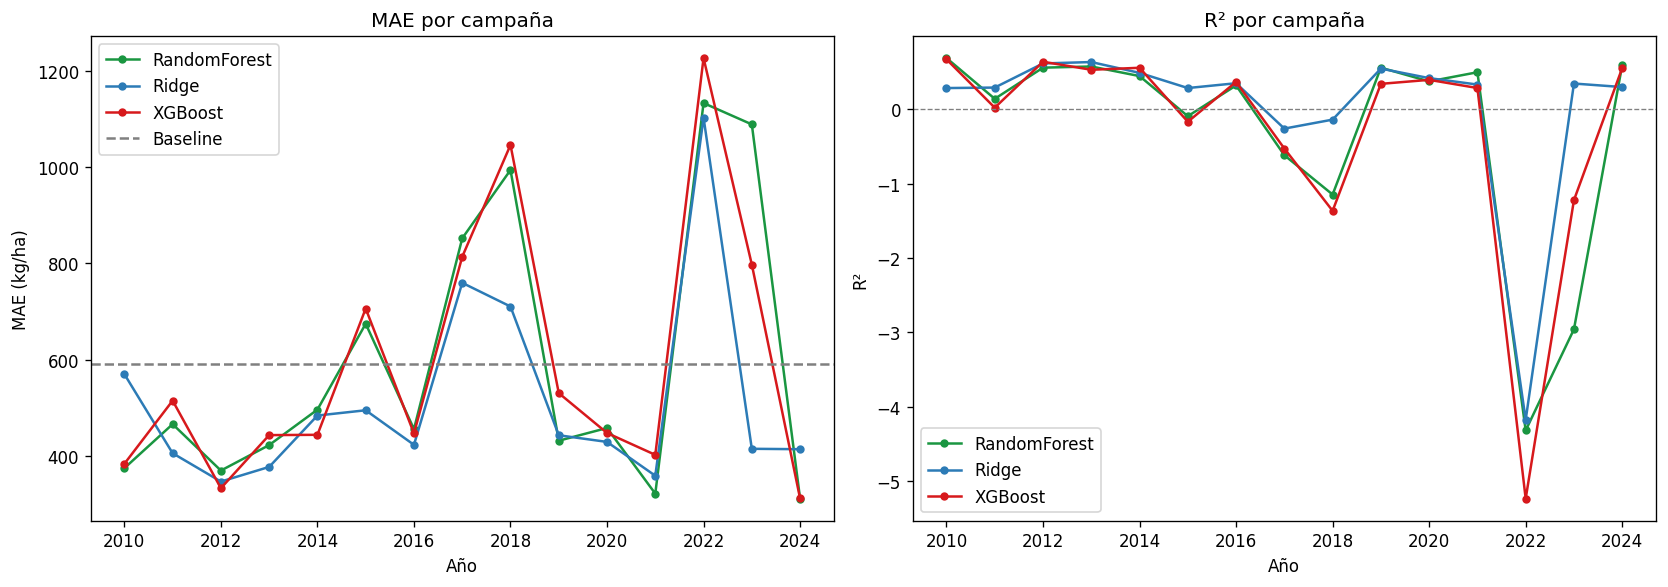

In [23]:
# Visualización MAE y R² por campaña
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colores = {'Ridge': '#2C7BB6', 'RandomForest': '#1A9641', 'XGBoost': '#D7191C'}

for modelo, grp in df_res.groupby('modelo'):
    axes[0].plot(grp['anio'], grp['mae'], marker='o', label=modelo,
                 color=colores[modelo], linewidth=1.5, markersize=4)
axes[0].axhline(mae_baseline, color='gray', linestyle='--', label='Baseline')
axes[0].set_title('MAE por campaña'); axes[0].set_xlabel('Año')
axes[0].set_ylabel('MAE (kg/ha)'); axes[0].legend()

for modelo, grp in df_res.groupby('modelo'):
    axes[1].plot(grp['anio'], grp['r2'], marker='o', label=modelo,
                 color=colores[modelo], linewidth=1.5, markersize=4)
axes[1].axhline(0, color='gray', linestyle='--', linewidth=0.8)
axes[1].set_title('R² por campaña'); axes[1].set_xlabel('Año'); axes[1].set_ylabel('R²'); axes[1].legend()

plt.tight_layout()
plt.savefig(f'{DRIVE_ROOT}/outputs/figures/walk_forward_resultados.png', bbox_inches='tight')
plt.show()

In [24]:
# Análisis por fase ENSO
df_res_enso = df_res.merge(df_enso[['anio', 'fase_enso']], on='anio', how='left')

print("=== MAE promedio por fase ENSO (Ridge) ===")
print(df_res_enso[df_res_enso['modelo'] == 'Ridge']
      .groupby('fase_enso')[['mae', 'rmse']].mean().round(0))

print("\n=== MAE por año (Ridge) ===")
print(df_res_enso[df_res_enso['modelo'] == 'Ridge']
      [['anio', 'fase_enso', 'mae', 'r2']].sort_values('anio').to_string(index=False))

=== MAE promedio por fase ENSO (Ridge) ===
             mae   rmse
fase_enso              
Neutro    509.00 620.00
Niña      585.00 723.00
Niño      462.00 574.00

=== MAE por año (Ridge) ===
 anio fase_enso     mae    r2
 2010      Niño  569.94  0.29
 2011      Niña  405.40  0.29
 2012      Niña  346.49  0.62
 2013    Neutro  376.94  0.64
 2014    Neutro  483.79  0.49
 2015      Niño  494.75  0.29
 2016      Niño  422.90  0.35
 2017    Neutro  759.75 -0.26
 2018      Niña  710.51 -0.14
 2019      Niño  442.80  0.55
 2020      Niño  428.95  0.42
 2021      Niña  358.60  0.33
 2022      Niña 1103.27 -4.18
 2023    Neutro  414.62  0.35
 2024      Niño  413.78  0.30


In [25]:
# Métricas excluyendo 2022 (sequía histórica sin precedentes en período de entrenamiento)
df_sin_2022 = df_res_enso[(df_res_enso['modelo'] == 'Ridge') & (df_res_enso['anio'] != 2022)]
print("=== Ridge excluyendo 2022 ===")
print(f"MAE:  {df_sin_2022['mae'].mean():.0f} kg/ha")
print(f"RMSE: {df_sin_2022['rmse'].mean():.0f} kg/ha")
print(f"R²:   {df_sin_2022['r2'].mean():.3f}")

=== Ridge excluyendo 2022 ===
MAE:  474 kg/ha
RMSE: 590 kg/ha
R²:   0.322


### Distribución espacial del error del modelo

Se analiza cómo varía espacialmente el error de predicción. Los mapas permiten identificar departamentos con mayores o menores errores medios y observar específicamente el comportamiento del modelo durante la campaña 2022.


In [26]:
# Calcular MAE por departamento del walk-forward
df_pred_depto = []
for anio_test in range(ANIO_INICIO_VAL, ANIO_FIN + 1):
    df_train = df_model[df_model['anio'] < anio_test]
    df_test  = df_model[df_model['anio'] == anio_test]
    if len(df_train) == 0 or len(df_test) == 0: continue

    X_train, y_train = df_train[FEATURES], df_train[TARGET]
    X_test,  y_test  = df_test[FEATURES],  df_test[TARGET]
    sc = StandardScaler()
    X_train_sc = sc.fit_transform(X_train)
    X_test_sc  = sc.transform(X_test)

    ridge = Ridge(alpha=1.0)
    ridge.fit(X_train_sc, y_train)
    preds = ridge.predict(X_test_sc)

    df_tmp = df_test[['departamento', 'provincia', 'anio']].copy()
    df_tmp['pred']      = preds
    df_tmp['real']      = y_test.values
    df_tmp['error_abs'] = np.abs(preds - y_test.values)
    df_pred_depto.append(df_tmp)

df_pred_depto = pd.concat(df_pred_depto)
print(f"Predicciones generadas: {len(df_pred_depto)}")

Predicciones generadas: 2454


Guardado: /content/drive/MyDrive/tesina_soja/outputs/figures/mapa_05_mae_por_depto.png


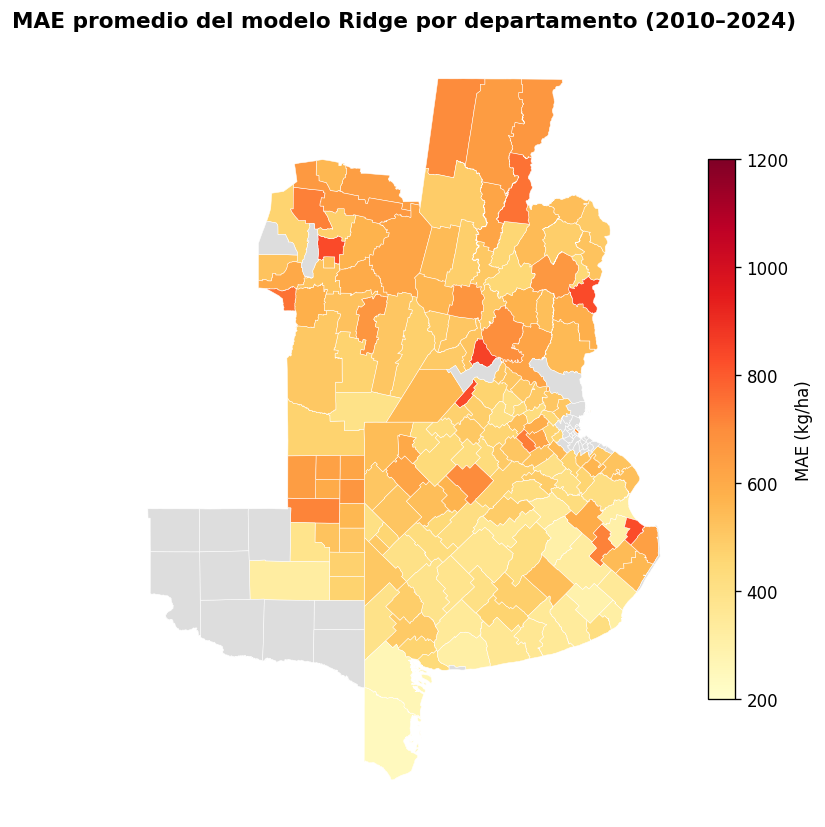

In [27]:
# MAE promedio del modelo Ridge por departamento
# Guardamos las predicciones por departamento del walk-forward
# Reentrenamos brevemente para extraer predicciones por depto

df_pred_depto = []
for anio_test in range(ANIO_INICIO_VAL, ANIO_FIN + 1):
    df_train = df_map[df_map['anio'] < anio_test]
    df_test  = df_map[df_map['anio'] == anio_test]
    if len(df_train) == 0 or len(df_test) == 0: continue

    X_train, y_train = df_train[FEATURES], df_train[TARGET]
    X_test,  y_test  = df_test[FEATURES],  df_test[TARGET]
    sc = StandardScaler()
    X_train_sc = sc.fit_transform(X_train)
    X_test_sc  = sc.transform(X_test)

    ridge = Ridge(alpha=1.0)
    ridge.fit(X_train_sc, y_train)
    preds = ridge.predict(X_test_sc)

    df_tmp = df_test[['departamento', 'anio']].copy()
    df_tmp['pred']  = preds
    df_tmp['real']  = y_test.values
    df_tmp['error_abs'] = np.abs(preds - y_test.values)
    df_pred_depto.append(df_tmp)

df_pred_depto = pd.concat(df_pred_depto)

mae_depto = (df_pred_depto.groupby('departamento')['error_abs']
             .mean().reset_index().rename(columns={'error_abs': 'mae'}))

gdf_m5 = gdf_pampa.merge(mae_depto, on='departamento', how='left')

mapa(gdf_m5, 'mae',
     'MAE promedio del modelo Ridge por departamento (2010–2024)',
     cmap='YlOrRd', vmin=200, vmax=1200,
     label_cbar='MAE (kg/ha)',
     fname='mapa_05_mae_por_depto.png')

Guardado: /content/drive/MyDrive/tesina_soja/outputs/figures/mapa_06_error_2022.png


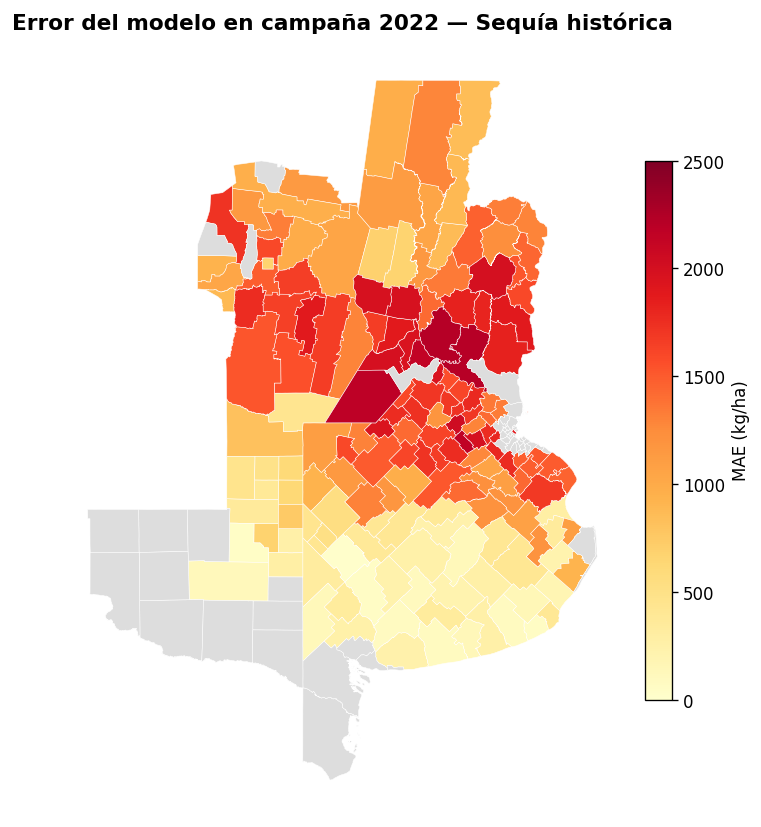

In [28]:
# Error del modelo en 2022 (sequía histórica)
error_2022 = (df_pred_depto[df_pred_depto['anio'] == 2022]
              .groupby('departamento')['error_abs']
              .mean().reset_index()
              .rename(columns={'error_abs': 'mae_2022'}))

gdf_m6 = gdf_pampa.merge(error_2022, on='departamento', how='left')

mapa(gdf_m6, 'mae_2022',
     'Error del modelo en campaña 2022 — Sequía histórica',
     cmap='YlOrRd', vmin=0, vmax=2500,
     label_cbar='MAE (kg/ha)',
     fname='mapa_06_error_2022.png')

## 14. Aporte marginal del NDVI

Se compara el desempeño del modelo principal con una versión que incorpora NDVI. El objetivo es determinar si la información satelital agrega valor predictivo una vez incorporadas las variables climáticas y ENSO.


In [29]:
# Merge fuzzy de nombres de departamentos entre NDVI (FAO) y magyp
import unicodedata

def normalizar(s):
    s = s.lower().strip()
    s = unicodedata.normalize('NFD', s)
    return ''.join(c for c in s if unicodedata.category(c) != 'Mn')

deptos_ndvi  = set(df_ndvi['departamento'].unique())
deptos_model = set(df_model['departamento'].unique())
ndvi_norm    = {normalizar(d): d for d in deptos_ndvi}
model_norm   = {normalizar(d): d for d in deptos_model}

mapeo = {}
for norm_m, orig_m in model_norm.items():
    if norm_m in ndvi_norm: mapeo[orig_m] = ndvi_norm[norm_m]
    else:
        matches = get_close_matches(norm_m, ndvi_norm.keys(), n=1, cutoff=0.75)
        if matches: mapeo[orig_m] = ndvi_norm[matches[0]]

df_model['depto_ndvi'] = df_model['departamento'].map(mapeo)
df_model_ndvi = df_model.merge(df_ndvi.rename(columns={'departamento': 'depto_ndvi'}),
                                on=['depto_ndvi', 'anio'], how='left')
FEATURES_NDVI = FEATURES + ['ndvi_max']
df_model_ndvi = df_model_ndvi.dropna(subset=FEATURES_NDVI + [TARGET])

print(f"Cobertura NDVI: {df_model_ndvi['ndvi_max'].notna().mean()*100:.1f}% ({len(df_model_ndvi)} registros)")

Cobertura NDVI: 100.0% (4345 registros)


In [30]:
# Walk-forward con NDVI
resultados_ndvi = []
for anio_test in range(ANIO_INICIO_VAL, ANIO_FIN + 1):
    df_train = df_model_ndvi[df_model_ndvi['anio'] < anio_test]
    df_test  = df_model_ndvi[df_model_ndvi['anio'] == anio_test]
    if len(df_train) == 0 or len(df_test) == 0: continue

    X_train, y_train = df_train[FEATURES_NDVI], df_train[TARGET]
    X_test,  y_test  = df_test[FEATURES_NDVI],  df_test[TARGET]
    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc  = scaler.transform(X_test)

    for nombre, modelo in modelos.items():
        if nombre == 'Ridge':
            modelo.fit(X_train_sc, y_train); preds = modelo.predict(X_test_sc)
        else:
            modelo.fit(X_train, y_train); preds = modelo.predict(X_test)
        mae  = mean_absolute_error(y_test, preds)
        rmse = mean_squared_error(y_test, preds)**0.5
        r2   = 1 - ((y_test - preds)**2).sum() / ((y_test - y_test.mean())**2).sum()
        resultados_ndvi.append({'anio': anio_test, 'modelo': nombre, 'mae': mae, 'rmse': rmse, 'r2': r2})

df_res_ndvi = pd.DataFrame(resultados_ndvi)
resumen_ndvi = df_res_ndvi.groupby('modelo')[['mae', 'rmse', 'r2']].mean().round(1).sort_values('mae')
resumen_base = df_res.groupby('modelo')[['mae', 'rmse', 'r2']].mean().round(1).sort_values('mae')

print("=== Aporte marginal del NDVI ===")
print(f"{'Modelo':<15} {'MAE':>10} {'RMSE':>10} {'R²':>8}")
print("-" * 46)
print("── Sin NDVI ──")
for nombre, row in resumen_base.iterrows():
    print(f"{nombre:<15} {row['mae']:>10.0f} {row['rmse']:>10.0f} {row['r2']:>8.3f}")
print("── Con NDVI ──")
for nombre, row in resumen_ndvi.iterrows():
    print(f"{nombre:<15} {row['mae']:>10.0f} {row['rmse']:>10.0f} {row['r2']:>8.3f}")
print("-" * 46)
print(f"{'Baseline':<15} {mae_baseline:>10.0f} {rmse_baseline:>10.0f} {'—':>8}")

=== Aporte marginal del NDVI ===
Modelo                 MAE       RMSE       R²
----------------------------------------------
── Sin NDVI ──
Ridge                  516        636    0.000
XGBoost                590        708   -0.300
RandomForest           590        708   -0.300
── Con NDVI ──
Ridge                  519        641    0.000
RandomForest           542        664   -0.000
XGBoost                556        677   -0.100
----------------------------------------------
Baseline               591        734        —


## 15. Guardar modelo y resultados

Se genera el modelo final con el conjunto de variables seleccionado y se guardan los resultados y artefactos necesarios para conservar el producto del análisis y facilitar su reutilización.


In [31]:
# Modelo final: Ridge entrenado sobre todo el dataset
scaler_final = StandardScaler()
X_final_sc = scaler_final.fit_transform(df_model_ndvi[FEATURES])
ridge_final = Ridge(alpha=1.0)
ridge_final.fit(X_final_sc, df_model_ndvi[TARGET])

with open(f'{DRIVE_ROOT}/processed/ridge_final.pkl', 'wb') as f:
    pickle.dump({'modelo': ridge_final, 'scaler': scaler_final, 'features': FEATURES}, f)

df_model_ndvi.to_parquet(f'{DRIVE_ROOT}/processed/dataset_final.parquet', index=False)
df_res.to_parquet(f'{DRIVE_ROOT}/processed/resultados_walkforward.parquet', index=False)

print("Guardado en Drive:")
print(f"  {DRIVE_ROOT}/processed/ridge_final.pkl")
print(f"  {DRIVE_ROOT}/processed/dataset_final.parquet")
print(f"  {DRIVE_ROOT}/processed/resultados_walkforward.parquet")

Guardado en Drive:
  /content/drive/MyDrive/tesina_soja/processed/ridge_final.pkl
  /content/drive/MyDrive/tesina_soja/processed/dataset_final.parquet
  /content/drive/MyDrive/tesina_soja/processed/resultados_walkforward.parquet


## 16. Contraste Operativo a Escala de Lote

Como contraste adicional, se evalúa el comportamiento del modelo frente a datos de lotes individuales. Esta etapa permite comparar una predicción desarrollada a escala departamental con observaciones de una escala espacial más detallada y cuantificar la diferencia de desempeño.


In [32]:
# Cargar datos de lotes desde Drive
RUTA_LOTES = f'{DRIVE_ROOT}/raw/rendimiento_soja_procesado.csv'

df_lotes = pd.read_csv(RUTA_LOTES)

# Filtrar años que el modelo puede predecir (2010 en adelante)
df_lotes = df_lotes[df_lotes['anio'].between(ANIO_INICIO_VAL, ANIO_FIN)].copy()

print(f"Registros de lotes para contrastar: {len(df_lotes)}")
print(f"Campañas: {sorted(df_lotes['anio'].unique())}")
print(f"Departamentos: {df_lotes['departamento'].nunique()}")

Registros de lotes para contrastar: 205
Campañas: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
Departamentos: 54


In [33]:
# Generar predicciones del modelo para cada departamento-año
# Usamos el dataset del modelo para extraer las features de cada depto-año
# y aplicar el Ridge final entrenado

# Cargar modelo y dataset si no están en memoria
import pickle
with open(f'{DRIVE_ROOT}/processed/ridge_final.pkl', 'rb') as f:
    checkpoint = pickle.load(f)
ridge_final  = checkpoint['modelo']
scaler_final = checkpoint['scaler']
FEATURES     = checkpoint['features']

df_dataset = pd.read_parquet(f'{DRIVE_ROOT}/processed/dataset_final.parquet')

if 'provincia_x' in df_dataset.columns:
    df_dataset = df_dataset.rename(columns={'provincia_x': 'provincia'})

# Obtener predicción para cada depto-año disponible en el dataset
df_pred = df_dataset[['departamento', 'provincia', 'anio'] + FEATURES].drop_duplicates().copy()
X_pred = scaler_final.transform(df_pred[FEATURES])
df_pred['prediccion_kgha'] = ridge_final.predict(X_pred)

print(f"Predicciones generadas: {len(df_pred)}")
display(df_pred[['departamento', 'provincia', 'anio', 'prediccion_kgha']].head())

Predicciones generadas: 4021


,departamento,provincia,anio,prediccion_kgha
0,Carlos Tejedor,Buenos Aires,2000,2672.08
1,Carlos Casares,Buenos Aires,2000,2932.39
2,Capitán Sarmiento,Buenos Aires,2000,3232.89
3,Cañuelas,Buenos Aires,2000,3025.92
4,Alberti,Buenos Aires,2000,3199.61


In [34]:
# Merge lotes con predicciones
df_contraste = df_lotes.merge(
    df_pred[['departamento', 'provincia', 'anio', 'prediccion_kgha']],
    on=['departamento', 'provincia', 'anio'],
    how='left'
)

sin_pred = df_contraste['prediccion_kgha'].isna().sum()
print(f"Lotes con predicción: {df_contraste['prediccion_kgha'].notna().sum()}")
print(f"Lotes sin predicción: {sin_pred}")
if sin_pred > 0:
    print("Departamentos sin predicción:")
    print(df_contraste[df_contraste['prediccion_kgha'].isna()][['departamento', 'anio']].drop_duplicates())

Lotes con predicción: 197
Lotes sin predicción: 8
Departamentos sin predicción:
       departamento  anio
26   Nueve de Julio  2021
70   Nueve de Julio  2022
111  Nueve de Julio  2023
134   Marcos Juárez  2023
160  Nueve de Julio  2024
161      Marcos Paz  2024


In [35]:
# Métricas del contraste
df_ok = df_contraste.dropna(subset=['prediccion_kgha']).copy()
df_ok['error'] = df_ok['rinde_lote'] - df_ok['prediccion_kgha']
df_ok['error_abs'] = df_ok['error'].abs()

mae_contraste  = df_ok['error_abs'].mean()
rmse_contraste = (df_ok['error']**2).mean()**0.5
r2_contraste   = 1 - ((df_ok['error']**2).sum() /
                       ((df_ok['rinde_lote'] - df_ok['rinde_lote'].mean())**2).sum())

print("=== Contraste operativo a escala de lote ===")
print(f"Registros comparados: {len(df_ok)}")
print(f"MAE:  {mae_contraste:.0f} kg/ha")
print(f"RMSE: {rmse_contraste:.0f} kg/ha")
print(f"R²:   {r2_contraste:.3f}")
print(f"\nModelo departamental (walk-forward): MAE ~515 kg/ha")
print(f"Incremento de error a escala lote:   {mae_contraste - 515:+.0f} kg/ha")

=== Contraste operativo a escala de lote ===
Registros comparados: 197
MAE:  1134 kg/ha
RMSE: 1465 kg/ha
R²:   -0.168

Modelo departamental (walk-forward): MAE ~515 kg/ha
Incremento de error a escala lote:   +619 kg/ha


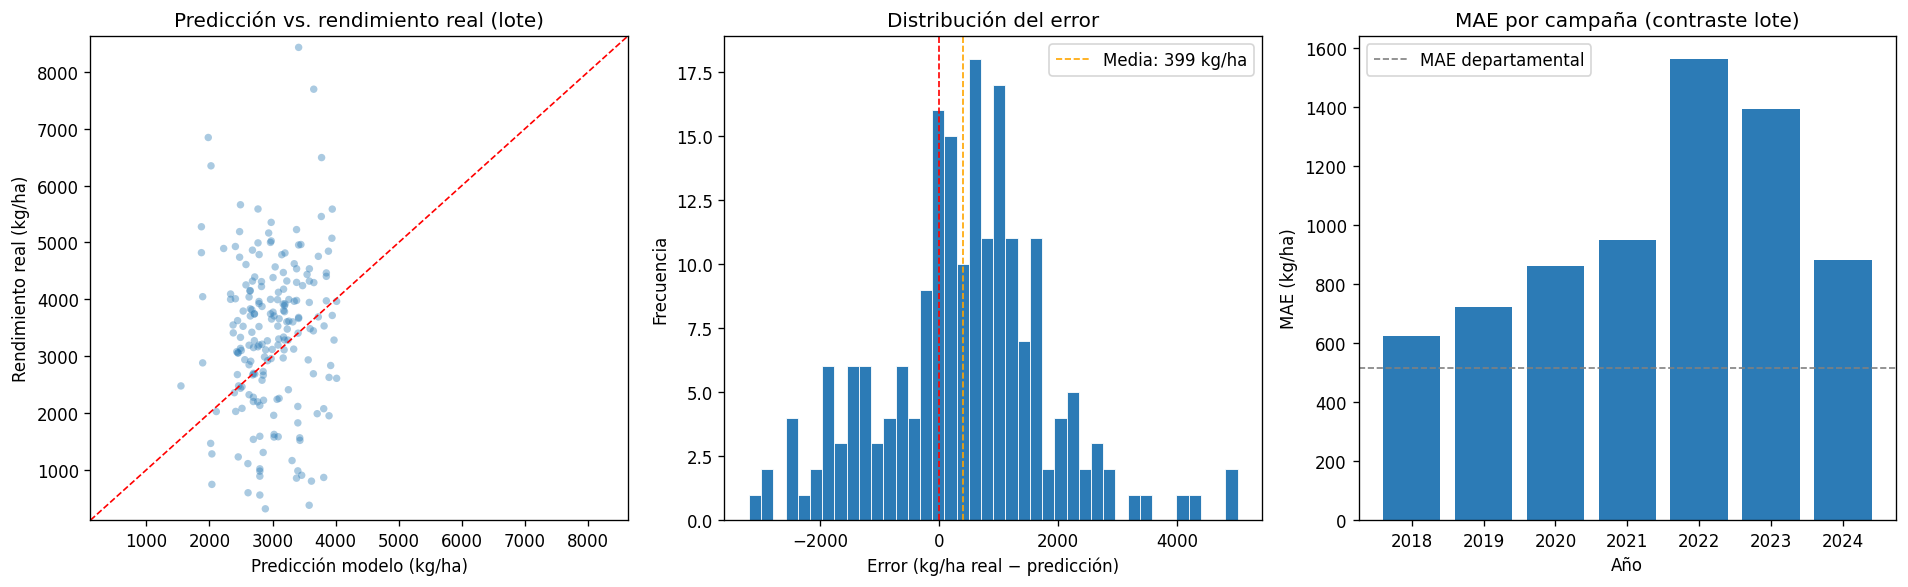

In [36]:
# Visualización
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Predicción vs real
axes[0].scatter(df_ok['prediccion_kgha'], df_ok['rinde_lote'],
                alpha=0.4, color='#2C7BB6', edgecolors='none', s=20)
lim = [df_ok[['prediccion_kgha', 'rinde_lote']].min().min() - 200,
       df_ok[['prediccion_kgha', 'rinde_lote']].max().max() + 200]
axes[0].plot(lim, lim, 'r--', linewidth=1)
axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_title('Predicción vs. rendimiento real (lote)')
axes[0].set_xlabel('Predicción modelo (kg/ha)')
axes[0].set_ylabel('Rendimiento real (kg/ha)')

# Distribución del error
axes[1].hist(df_ok['error'], bins=40, color='#2C7BB6', edgecolor='white', linewidth=0.5)
axes[1].axvline(0, color='red', linestyle='--', linewidth=1)
axes[1].axvline(df_ok['error'].mean(), color='orange', linestyle='--',
                linewidth=1, label=f"Media: {df_ok['error'].mean():.0f} kg/ha")
axes[1].set_title('Distribución del error')
axes[1].set_xlabel('Error (kg/ha real − predicción)')
axes[1].set_ylabel('Frecuencia')
axes[1].legend()

# MAE por campaña
mae_anio = df_ok.groupby('anio')['error_abs'].mean()
axes[2].bar(mae_anio.index, mae_anio.values, color='#2C7BB6')
axes[2].axhline(515, color='gray', linestyle='--', linewidth=1, label='MAE departamental')
axes[2].set_title('MAE por campaña (contraste lote)')
axes[2].set_xlabel('Año')
axes[2].set_ylabel('MAE (kg/ha)')
axes[2].legend()

plt.tight_layout()
plt.savefig(f'{DRIVE_ROOT}/outputs/figures/contraste_lotes.png', bbox_inches='tight')
plt.show()

In [37]:
# Análisis por provincia y campaña
print("=== MAE por provincia ===")
print(df_ok.groupby('provincia')['error_abs'].mean().round(0).sort_values())

print("\n=== MAE por campaña ===")
df_mae_anio = df_ok.groupby('anio').agg(
    mae=('error_abs', 'mean'),
    n=('error_abs', 'count')
).round(0)
print(df_mae_anio)

# Guardar resultado del contraste
df_contraste.to_parquet(f'{DRIVE_ROOT}/processed/contraste_lotes.parquet', index=False)
print("\nResultado guardado en Drive.")

=== MAE por provincia ===
provincia
Córdoba        1097.00
Buenos Aires   1114.00
Santa Fe       1164.00
La Pampa       1250.00
Name: error_abs, dtype: float64

=== MAE por campaña ===
         mae   n
anio            
2018  626.00   3
2019  724.00   7
2020  862.00   8
2021  950.00  38
2022 1563.00  36
2023 1393.00  48
2024  881.00  57

Resultado guardado en Drive.


### Distribución espacial del sesgo operativo

Se representa espacialmente el sesgo observado en el contraste a escala de lote, definido a partir de la diferencia entre el rendimiento real y la predicción del modelo. El objetivo es complementar las métricas agregadas con una lectura geográfica del comportamiento del error.


Guardado: /content/drive/MyDrive/tesina_soja/outputs/figures/mapa_08_sesgo_contraste.png


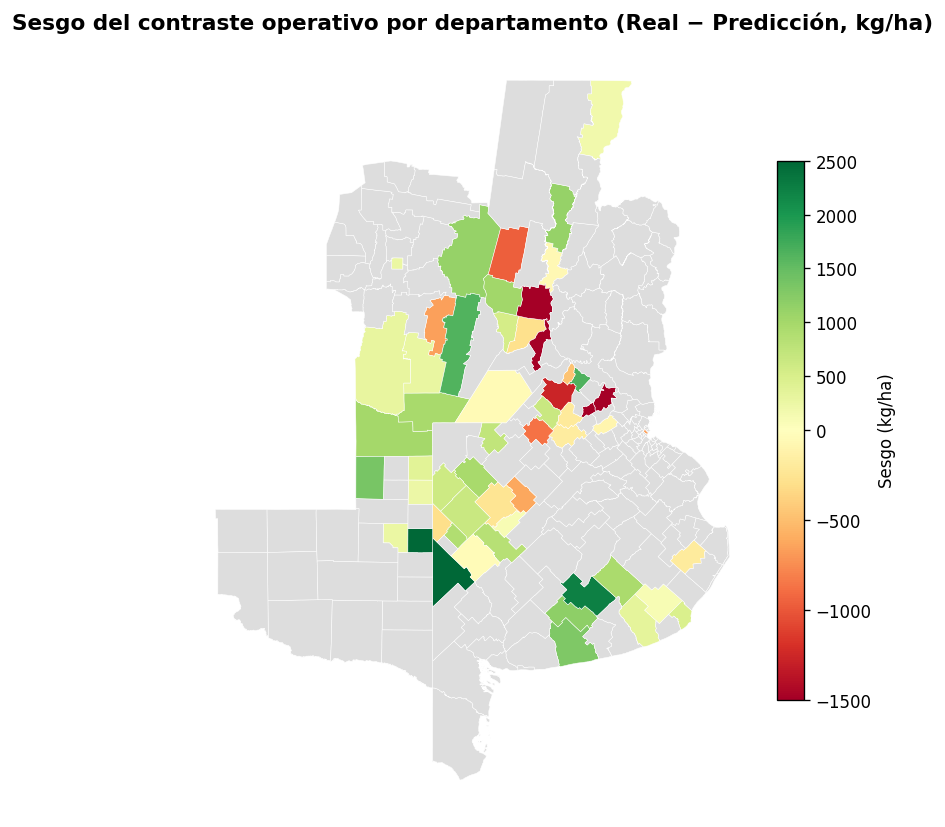


=== Todos los mapas generados ===
  ✓ Mapa 1: mapa_01_rinde_promedio.png
  ✓ Mapa 2: mapa_02_variabilidad.png
  ✓ Mapa 3: mapa_03_rinde_por_enso.png
  ✓ Mapa 4: mapa_04_diff_nino_nina.png
  ✓ Mapa 5: mapa_05_mae_por_depto.png
  ✓ Mapa 6: mapa_06_error_2022.png
  ✓ Mapa 7: mapa_07_ndvi_promedio.png
  ✓ Mapa 8: mapa_08_sesgo_contraste.png


In [38]:
# Sesgo del contraste operativo por departamento
# (solo departamentos con datos de lote)
df_contraste = pd.read_parquet(f'{DRIVE_ROOT}/processed/contraste_lotes.parquet')
df_contraste_ok = df_contraste.dropna(subset=['prediccion_kgha']).copy()
df_contraste_ok['sesgo'] = df_contraste_ok['rinde_lote'] - df_contraste_ok['prediccion_kgha']

sesgo_depto = (df_contraste_ok.groupby('departamento')['sesgo']
               .mean().reset_index())

gdf_m8 = gdf_pampa.merge(sesgo_depto, on='departamento', how='left')

mapa(gdf_m8, 'sesgo',
     'Sesgo del contraste operativo por departamento (Real − Predicción, kg/ha)',
     cmap='RdYlGn', vcenter=0, vmin=-1500, vmax=2500,
     label_cbar='Sesgo (kg/ha)',
     fname='mapa_08_sesgo_contraste.png')

print("\n=== Todos los mapas generados ===")
for i in range(1, 9):
    ruta = f'{DRIVE_ROOT}/outputs/figures/mapa_0{i}_*.png'
    import glob
    archivos = glob.glob(ruta)
    if archivos:
        print(f"  ✓ Mapa {i}: {os.path.basename(archivos[0])}")

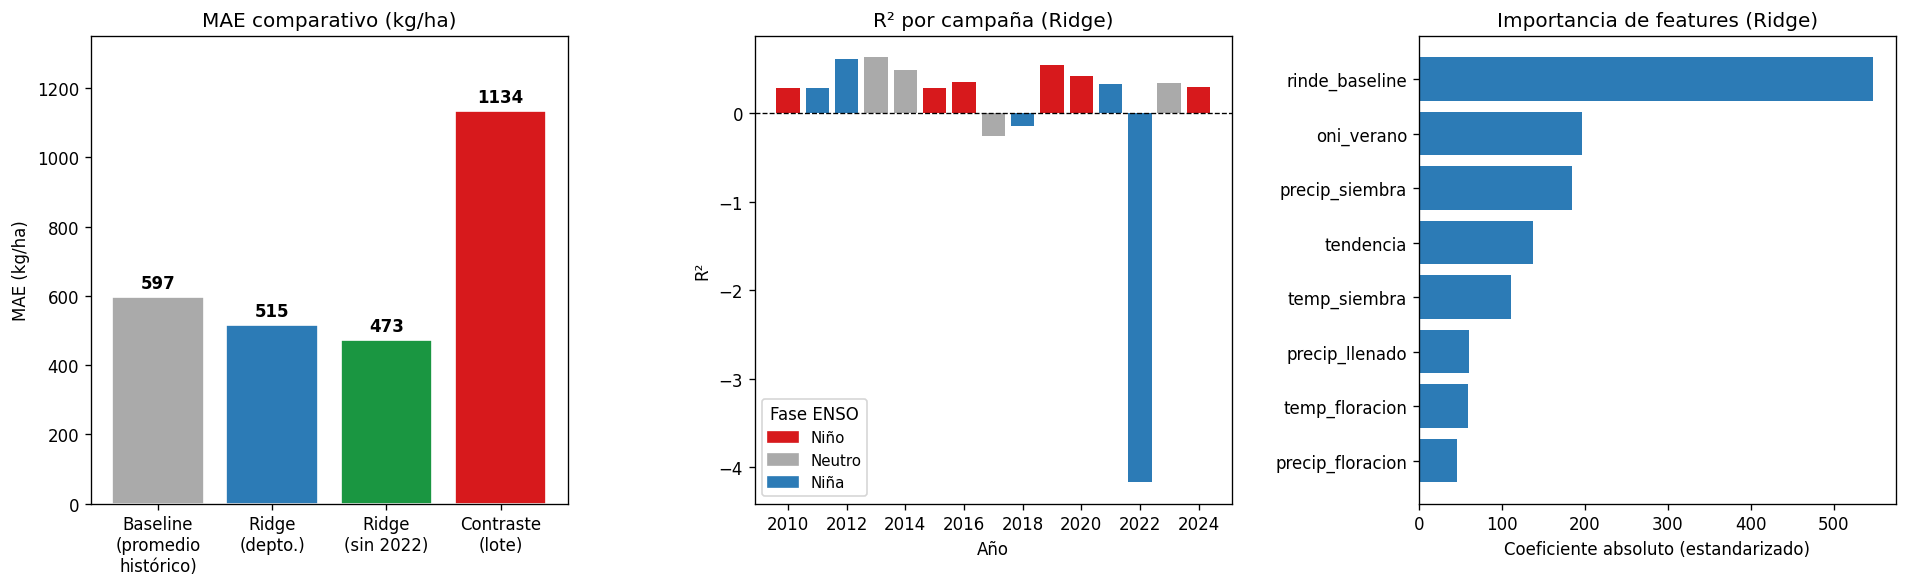

Figura guardada en Drive.


In [40]:
# Figura resumen final
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# MAE comparativo: baseline vs modelo vs lote
categorias = ['Baseline\n(promedio\nhistórico)', 'Ridge\n(depto.)', 'Ridge\n(sin 2022)', 'Contraste\n(lote)']
valores_mae = [597, 515, 473, 1134]
colores_bar = ['#AAAAAA', '#2C7BB6', '#1A9641', '#D7191C']

axes[0].bar(categorias, valores_mae, color=colores_bar, edgecolor='white')
for i, v in enumerate(valores_mae):
    axes[0].text(i, v + 15, f'{v}', ha='center', va='bottom', fontsize=10, fontweight='bold')
axes[0].set_title('MAE comparativo (kg/ha)')
axes[0].set_ylabel('MAE (kg/ha)')
axes[0].set_ylim(0, 1350)

# R² por campaña (Ridge sin NDVI)
df_ridge = df_res[df_res['modelo'] == 'Ridge'].copy()
df_ridge = df_ridge.merge(df_enso[['anio', 'fase_enso']], on='anio', how='left')
colores_enso = {'Niño': '#D7191C', 'Neutro': '#AAAAAA', 'Niña': '#2C7BB6'}
bars = axes[1].bar(df_ridge['anio'], df_ridge['r2'],
                   color=df_ridge['fase_enso'].map(colores_enso))
axes[1].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[1].set_title('R² por campaña (Ridge)')
axes[1].set_xlabel('Año')
axes[1].set_ylabel('R²')
# Leyenda manual
from matplotlib.patches import Patch
leyenda = [Patch(color=c, label=f) for f, c in colores_enso.items()]
axes[1].legend(handles=leyenda, title='Fase ENSO', fontsize=9)

# Importancia de features
scaler_imp = StandardScaler()
X_imp = df_model[FEATURES]
y_imp = df_model[TARGET]
ridge_imp = Ridge(alpha=1.0)
ridge_imp.fit(scaler_imp.fit_transform(X_imp), y_imp)
importancias = pd.Series(abs(ridge_imp.coef_), index=FEATURES).sort_values()
axes[2].barh(importancias.index, importancias.values, color='#2C7BB6')
axes[2].set_title('Importancia de features (Ridge)')
axes[2].set_xlabel('Coeficiente absoluto (estandarizado)')

plt.tight_layout()
plt.savefig(f'{DRIVE_ROOT}/outputs/figures/resumen_final.png', bbox_inches='tight', dpi=150)
plt.show()
print("Figura guardada en Drive.")

In [41]:
# Guardar todo
df_contraste.to_parquet(f'{DRIVE_ROOT}/processed/contraste_lotes.parquet', index=False)
df_res.to_parquet(f'{DRIVE_ROOT}/processed/resultados_walkforward.parquet', index=False)

print("=== Archivos en Drive ===")
for root, dirs, files in os.walk(DRIVE_ROOT):
    nivel = root.replace(DRIVE_ROOT, '').count(os.sep)
    indent = '  ' * nivel
    carpeta = os.path.basename(root)
    print(f"{indent}{carpeta}/")
    for f in sorted(files):
        size = os.path.getsize(os.path.join(root, f)) / 1024
        print(f"{indent}  {f} ({size:.0f} KB)")

=== Archivos en Drive ===
tesina_soja/
  tesina_soja_v4 (2).ipynb (65 KB)
  raw/
    magyp_estimaciones.csv (12042 KB)
    oni.csv (13 KB)
    rendimiento_soja_procesado.csv (23 KB)
    era5/
      era5_2000_2024.zip (2230 KB)
      era5_precipitacion.nc (1131 KB)
      era5_temperatura.nc (1098 KB)
    ndvi/
    shp/
      deptos_indec.gpkg (9288 KB)
    era5_v7/
  processed/
    contraste_lotes.parquet (10 KB)
    dataset_final.parquet (215 KB)
    dataset_modelo.parquet (251 KB)
    enso_por_campania.parquet (3 KB)
    enso_por_campania_v7.parquet (4 KB)
    era5_departamentos.parquet (202 KB)
    magyp_soja_pampa.parquet (80 KB)
    magyp_soja_pampa_v7.parquet (80 KB)
    resultados_walkforward.parquet (4 KB)
    ridge_final.pkl (1 KB)
  outputs/
    conclusiones.txt (2 KB)
    figures/
      contraste_lotes.png (110 KB)
      eda_magyp.png (80 KB)
      mapa_01_rinde_promedio.png (173 KB)
      mapa_02_variabilidad.png (170 KB)
      mapa_03_rinde_por_enso.png (373 KB)
      mapa_